In [1]:
from pathlib import Path
import json
import os
import sys
import importlib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
LABEL_COLUMN = "subCategory"
MAX_EXPLANATIONS = 3

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (folder for folder in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (folder / "notebooks").is_dir() and (folder / "src").is_dir()),
    CURRENT_DIR
)

MODEL_DIR = PROJECT_DIR / "models" / "cv"
MODEL_PATH = MODEL_DIR / "retailmind_transfer_learning.keras"
CLASS_NAMES_PATH = MODEL_DIR / "retailmind_transfer_classes.json"
DATASET_DIR = PROJECT_DIR / "data" / "fashion_product_images_small"
DATASET_CSV = DATASET_DIR / "styles.csv"
IMAGE_DIR = DATASET_DIR / "images"
SRC_DIR = PROJECT_DIR / "src"
REPORT_DIR = PROJECT_DIR / "reports" / "day8_gradcam"

SRC_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Day 7 model was not found at {MODEL_PATH}. Run the Day 7 notebook first and make sure training completed."
    )

if not CLASS_NAMES_PATH.is_file():
    raise FileNotFoundError(
        f"Class names file was not found at {CLASS_NAMES_PATH}. Run the save-model cell in Day 7 first."
    )

print("Project folder:", PROJECT_DIR)
print("Day 7 model:", MODEL_PATH)
print("Class names:", CLASS_NAMES_PATH)
print("TensorFlow:", tf.__version__)

Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Day 7 model: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras
Class names: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_classes.json
TensorFlow: 2.22.0-rc0


In [2]:
with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    class_names = json.load(file)

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

input_shape = model.input_shape
if isinstance(input_shape, list):
    input_shape = input_shape[0]

IMAGE_SIZE = (int(input_shape[1]), int(input_shape[2]))

if len(class_names) != int(model.output_shape[-1]):
    raise ValueError(
        "The saved class-name list does not match the number of model outputs. "
        "Use the model and class-name JSON saved together by Day 7."
    )

print("Loaded Day 7 MobileNetV2 classifier successfully.")
print("Input image size:", IMAGE_SIZE)
print("Number of product categories:", len(class_names))
print("Categories:", class_names)
model.summary()

Loaded Day 7 MobileNetV2 classifier successfully.
Input image size: (160, 160)
Number of product categories: 20
Categories: ['Bags', 'Belts', 'Bottomwear', 'Dress', 'Eyewear', 'Flip Flops', 'Fragrance', 'Innerwear', 'Jewellery', 'Lips', 'Loungewear and Nightwear', 'Makeup', 'Nails', 'Sandal', 'Saree', 'Shoes', 'Socks', 'Topwear', 'Wallets', 'Watches']


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,424,532 (9.25 MB)

 Trainable params: 166,548 (650.58 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [3]:
if not DATASET_CSV.is_file():
    raise FileNotFoundError(
        f"The Day 7 dataset CSV was not found at {DATASET_CSV}. "
        "Run the dataset setup cell from Day 7 or update DATASET_CSV in this cell."
    )

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"The product image folder was not found at {IMAGE_DIR}. "
        "Check that the Fashion Product Images dataset is stored in data/fashion_product_images_small/."
    )

styles = pd.read_csv(DATASET_CSV, dtype={"id": "string"}, on_bad_lines="skip")
styles.columns = styles.columns.str.strip()

required_columns = {"id", LABEL_COLUMN}
missing_columns = required_columns.difference(styles.columns)
if missing_columns:
    raise ValueError(f"Missing required columns in styles.csv: {sorted(missing_columns)}")

catalog = styles.dropna(subset=["id", LABEL_COLUMN]).copy()
catalog["id"] = catalog["id"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
catalog[LABEL_COLUMN] = catalog[LABEL_COLUMN].astype(str).str.strip()
catalog["image_path"] = catalog["id"].map(lambda image_id: str(IMAGE_DIR / f"{image_id}.jpg"))
catalog = catalog[catalog["image_path"].map(os.path.isfile)].copy()
catalog = catalog[catalog[LABEL_COLUMN].isin(class_names)].copy()

if catalog.empty:
    raise ValueError("No usable images matching the Day 7 product categories were found.")

sample_rows = []
for category in class_names:
    category_rows = catalog[catalog[LABEL_COLUMN] == category]
    if not category_rows.empty:
        sample_rows.append(category_rows.sample(n=1, random_state=SEED).iloc[0])
    if len(sample_rows) == MAX_EXPLANATIONS:
        break

if not sample_rows:
    raise ValueError("No sample product images are available for Grad-CAM.")

sample_images = pd.DataFrame(sample_rows).reset_index(drop=True)
print("Images selected for Grad-CAM:", len(sample_images))
print(sample_images[["id", LABEL_COLUMN, "image_path"]].to_string(index=False))

Images selected for Grad-CAM: 3
   id subCategory                                                                                     image_path
52581        Bags C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\images\52581.jpg
18565       Belts C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\images\18565.jpg
11279  Bottomwear C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\images\11279.jpg


In [4]:
module_source = 'from pathlib import Path\nimport numpy as np\nimport tensorflow as tf\nimport matplotlib.pyplot as plt\n\n_COMPONENTS = {}\n\n\ndef _get_gradcam_components(model):\n    model_key = id(model)\n    if model_key in _COMPONENTS:\n        return _COMPONENTS[model_key]\n\n    backbone = None\n    for layer in model.layers:\n        if not isinstance(layer, tf.keras.Model):\n            continue\n        try:\n            layer.get_layer("out_relu")\n            backbone = layer\n            break\n        except ValueError:\n            continue\n\n    if backbone is None:\n        raise ValueError(\n            "A MobileNetV2 backbone with the out_relu layer was not found. "\n            "Load the transfer-learning model saved by Day 7."\n        )\n\n    last_conv_layer = backbone.get_layer("out_relu")\n    backbone_index = model.layers.index(backbone)\n    preprocessing_layers = model.layers[1:backbone_index]\n    convolution_model = tf.keras.Model(\n        inputs=backbone.inputs,\n        outputs=last_conv_layer.output\n    )\n    classification_layers = model.layers[backbone_index + 1:]\n\n    components = (preprocessing_layers, convolution_model, classification_layers)\n    _COMPONENTS[model_key] = components\n    return components\n\n\ndef explain_product_image(\n    image_path,\n    model,\n    class_names,\n    image_size=None,\n    alpha=0.4,\n    display=True,\n    save_path=None\n):\n    image_path = Path(image_path)\n    if not image_path.is_file():\n        raise FileNotFoundError(f"Product image was not found: {image_path}")\n\n    if image_size is None:\n        input_shape = model.input_shape\n        if isinstance(input_shape, list):\n            input_shape = input_shape[0]\n        image_size = (int(input_shape[1]), int(input_shape[2]))\n\n    image = tf.keras.utils.load_img(\n        image_path,\n        target_size=image_size,\n        color_mode="rgb"\n    )\n    image_array = tf.keras.utils.img_to_array(image).astype("float32")\n    image_batch = tf.expand_dims(image_array, axis=0)\n\n    probabilities = model(image_batch, training=False).numpy()[0]\n    predicted_index = int(np.argmax(probabilities))\n    predicted_category = class_names[predicted_index]\n    confidence = float(probabilities[predicted_index])\n\n    preprocessing_layers, convolution_model, classification_layers = _get_gradcam_components(model)\n\n    with tf.GradientTape() as tape:\n        preprocessed_image = image_batch\n        for layer in preprocessing_layers:\n            preprocessed_image = layer(preprocessed_image, training=False)\n        convolution_outputs = convolution_model(preprocessed_image, training=False)\n        tape.watch(convolution_outputs)\n\n        output = convolution_outputs\n        for layer in classification_layers:\n            output = layer(output, training=False)\n\n        class_score = output[:, predicted_index]\n\n    gradients = tape.gradient(class_score, convolution_outputs)\n    if gradients is None:\n        raise RuntimeError("Grad-CAM gradients could not be calculated for this model.")\n\n    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))\n    heatmap = tf.reduce_sum(convolution_outputs[0] * channel_weights, axis=-1)\n    heatmap = tf.maximum(heatmap, 0)\n    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())\n    heatmap = heatmap.numpy()\n\n    resized_heatmap = tf.image.resize(\n        heatmap[..., np.newaxis],\n        image_size\n    ).numpy().squeeze()\n    colored_heatmap = plt.get_cmap("jet")(resized_heatmap)[..., :3]\n    overlay = np.clip(\n        (1.0 - alpha) * (image_array / 255.0) + alpha * colored_heatmap,\n        0.0,\n        1.0\n    )\n\n    if display or save_path is not None:\n        figure, axes = plt.subplots(1, 3, figsize=(14, 4))\n        axes[0].imshow(image_array.astype("uint8"))\n        axes[0].set_title("Original image")\n        axes[1].imshow(resized_heatmap, cmap="jet")\n        axes[1].set_title("Grad-CAM heatmap")\n        axes[2].imshow(overlay)\n        axes[2].set_title("Heatmap overlay")\n\n        for axis in axes:\n            axis.axis("off")\n\n        figure.suptitle(\n            f"Prediction: {predicted_category} | Confidence: {confidence:.2%}"\n        )\n        figure.tight_layout()\n\n        if save_path is not None:\n            save_path = Path(save_path)\n            save_path.parent.mkdir(parents=True, exist_ok=True)\n            figure.savefig(save_path, dpi=150, bbox_inches="tight")\n\n        if display:\n            plt.show()\n        else:\n            plt.close(figure)\n\n    return {\n        "image_path": str(image_path),\n        "predicted_category": predicted_category,\n        "confidence": confidence,\n        "class_index": predicted_index,\n        "probabilities": probabilities,\n        "heatmap": heatmap,\n        "overlay": overlay\n    }\n'

module_path = SRC_DIR / "vision_explainer.py"
module_path.write_text(module_source, encoding="utf-8")
print("RetailMind explainability module created:", module_path)

RetailMind explainability module created: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\src\vision_explainer.py


In [5]:
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import vision_explainer
importlib.reload(vision_explainer)

explain_product_image = vision_explainer.explain_product_image
print("Grad-CAM function is ready:", explain_product_image.__name__)

Grad-CAM function is ready: explain_product_image


Actual category: Bags


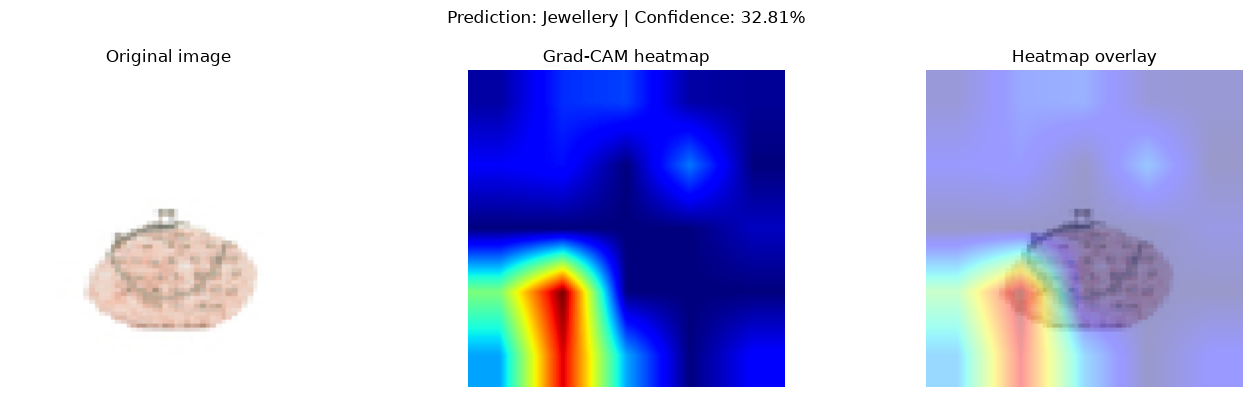

Predicted category: Jewellery
Confidence: 32.81%
Visualization saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day8_gradcam\gradcam_52581.png
------------------------------------------------------------
Actual category: Belts


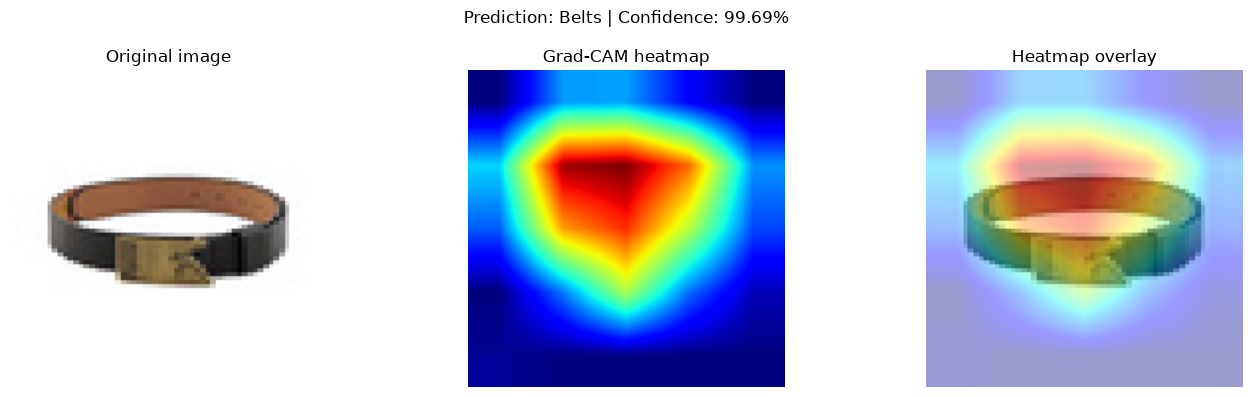

Predicted category: Belts
Confidence: 99.69%
Visualization saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day8_gradcam\gradcam_18565.png
------------------------------------------------------------
Actual category: Bottomwear


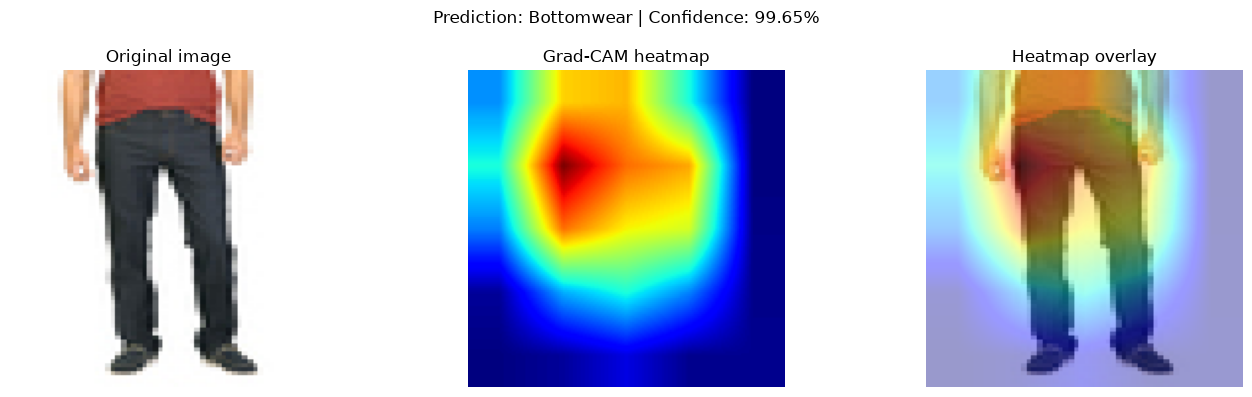

Predicted category: Bottomwear
Confidence: 99.65%
Visualization saved to: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day8_gradcam\gradcam_11279.png
------------------------------------------------------------
Grad-CAM examples completed: 3


In [6]:
explanation_results = []

for row in sample_images.itertuples(index=False):
    image_path = Path(row.image_path)
    actual_category = getattr(row, LABEL_COLUMN)
    output_path = REPORT_DIR / f"gradcam_{row.id}.png"

    print("Actual category:", actual_category)
    result = explain_product_image(
        image_path=image_path,
        model=model,
        class_names=class_names,
        image_size=IMAGE_SIZE,
        alpha=0.4,
        display=True,
        save_path=output_path
    )

    print("Predicted category:", result["predicted_category"])
    print(f"Confidence: {result['confidence']:.2%}")
    print("Visualization saved to:", output_path)
    print("-" * 60)
    explanation_results.append(result)

print("Grad-CAM examples completed:", len(explanation_results))

In [7]:
custom_image_path = None

if custom_image_path:
    custom_result = explain_product_image(
        image_path=custom_image_path,
        model=model,
        class_names=class_names,
        image_size=IMAGE_SIZE,
        alpha=0.4,
        display=True,
        save_path=REPORT_DIR / "custom_product_gradcam.png"
    )
    print("Prediction:", custom_result["predicted_category"])
    print(f"Confidence: {custom_result['confidence']:.2%}")
else:
    print("To explain your own product image, set custom_image_path to its file path and rerun this cell.")

To explain your own product image, set custom_image_path to its file path and rerun this cell.
